# Tutorial 10: Temporal attention for multivariate traffic forecasting

Tutorial 07 used one hour of flow, occupancy and speed from a PeMSD4 detector. Here we keep the same data and prediction target, but allow the model to inspect a longer history. An RNN carries information forward step by step; attention lets each time position connect directly to every historical position.

We first compute scaled dot-product attention explicitly, then compare a small temporal-attention model with persistence and a feed-forward ANN. Every figure labels what its axes and colours mean. The objective is not to build the largest Transformer; it is to understand what is weighted, how position is represented, and how a longer lookback is selected with validation data.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `10 Attention Mechanisms`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "10 Attention Mechanisms"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/10 Attention Mechanisms


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn torch


## Open the notebook

In [3]:
from pathlib import Path

if not Path("pems04_single_sensor.csv.gz").exists():
    !git clone -q https://github.com/JinTaoKe/AI-Code.git
    %cd "AI-Code/10 Attention Mechanisms"

In [4]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


## 1. Scaled dot-product attention by hand

For query matrix $Q$, key matrix $K$, and value matrix $V$, attention is $\operatorname{softmax}(QK^\top/\sqrt{d})V$. Row $i$ of the weight matrix answers: **when updating query position $i$, how much weight is assigned to every key position?** Every row therefore sums to one.

scaled similarity scores:
 [[0.71 0.   0.71]
 [0.   0.71 0.71]
 [0.71 0.71 1.41]]
each attention row sums to: [1. 1. 1.]
weighted output:
 [[6.42 4.38]
 [4.38 6.42]
 [5.5  5.5 ]]


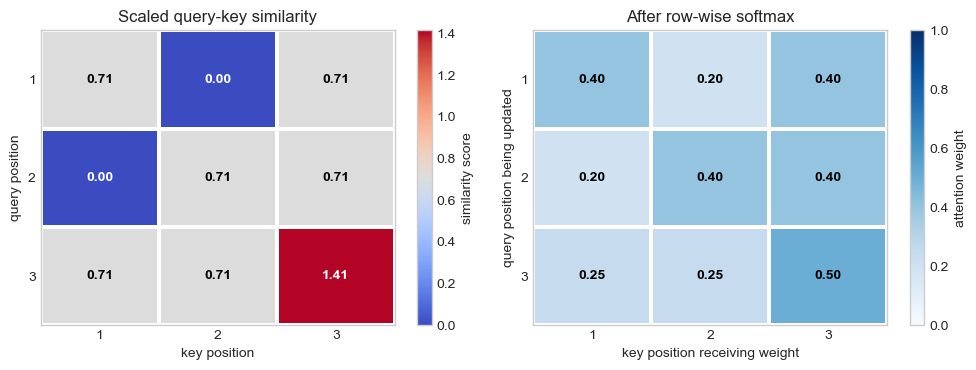

In [5]:
Q = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
K = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V = torch.tensor([[10.0, 0.0], [0.0, 10.0], [6.0, 6.0]])

scores = Q @ K.T / np.sqrt(Q.shape[1])
weights = torch.softmax(scores, dim=-1)
output = weights @ V

print("scaled similarity scores:\n", scores.numpy().round(2))
print("each attention row sums to:", weights.sum(dim=1).numpy())
print("weighted output:\n", output.numpy().round(2))

def draw_cell_matrix(ax, values, title, cmap, vmin=None, vmax=None, value_format=".2f"):
    """Draw one value per cell; ticks and labels are centred inside the cells."""
    values = np.asarray(values, dtype=float)
    n_rows, n_columns = values.shape
    image = ax.pcolormesh(
        np.arange(n_columns + 1),
        np.arange(n_rows + 1),
        values,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="flat",
        edgecolors="white",
        linewidth=1.5,
    )
    ax.set_xlim(0, n_columns)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks(np.arange(n_columns) + 0.5, np.arange(1, n_columns + 1))
    ax.set_yticks(np.arange(n_rows) + 0.5, np.arange(1, n_rows + 1))
    ax.grid(False)
    for row in range(n_rows):
        for column in range(n_columns):
            red, green, blue, _ = image.cmap(image.norm(values[row, column]))
            luminance = 0.299 * red + 0.587 * green + 0.114 * blue
            ax.text(
                column + 0.5,
                row + 0.5,
                format(values[row, column], value_format),
                ha="center",
                va="center",
                color="black" if luminance > 0.58 else "white",
                fontweight="bold",
            )
    ax.set_title(title)
    return image

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
score_image = draw_cell_matrix(
    axes[0], scores.numpy(), "Scaled query-key similarity", "coolwarm"
)
axes[0].set_xlabel("key position")
axes[0].set_ylabel("query position")
fig.colorbar(score_image, ax=axes[0], label="similarity score")

weight_image = draw_cell_matrix(
    axes[1], weights.numpy(), "After row-wise softmax", "Blues", vmin=0, vmax=1
)
axes[1].set_xlabel("key position receiving weight")
axes[1].set_ylabel("query position being updated")
fig.colorbar(weight_image, ax=axes[1], label="attention weight")
plt.tight_layout()

## 2. Build longer traffic sequences

Each five-minute token contains $D=3$ measurements from the same detector: flow, occupancy and speed. The target is one flow value one hour after the input window ends, exactly as in Tutorial 07.

We compare $T=12$ and $T=48$ on the validation period. These correspond to one and four hours of history. Attention can connect distant positions directly, but a longer window is useful only if validation performance improves.

In [6]:
traffic = pd.read_csv(
    "pems04_single_sensor.csv.gz",
    parse_dates=["time"],
).set_index("time")
traffic = traffic.iloc[:12000].copy()

train_end = 7500
valid_end = 9500
values = traffic.to_numpy(dtype="float32")
feature_mean = values[:train_end].mean(axis=0)
feature_std = values[:train_end].std(axis=0)
scaled_values = (values - feature_mean) / feature_std
flow_mean = float(feature_mean[0])
flow_std = float(feature_std[0])

print("Raw traffic table:", traffic.shape, "= (five-minute time steps, variables)")
print("Preview in original units: flow [vehicles/5 min], occupancy [fraction], and speed.")
display(traffic.head())
print("Scaling is used only for model fitting; metrics and prediction plots return to flow units.")

def make_windows(array, lookback, forecast_horizon):
    input_windows = []
    flow_targets = []
    target_positions = []

    first_target = lookback + forecast_horizon - 1
    for target_position in range(first_target, len(array)):
        input_end = target_position - forecast_horizon
        input_start = input_end - lookback + 1

        input_windows.append(array[input_start : input_end + 1])
        flow_targets.append(array[target_position, 0])
        target_positions.append(target_position)

    X = np.stack(input_windows).astype("float32")
    y = np.asarray(flow_targets, dtype="float32").reshape(-1, 1)
    target_positions = np.asarray(target_positions)
    return X, y, target_positions


def split_windows(lookback, forecast_horizon=12):
    X, y, target_positions = make_windows(
        scaled_values,
        lookback=lookback,
        forecast_horizon=forecast_horizon,
    )
    train_mask = target_positions < train_end
    valid_mask = (target_positions >= train_end) & (target_positions < valid_end)
    test_mask = target_positions >= valid_end

    return {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "X_valid": X[valid_mask],
        "y_valid": y[valid_mask],
        "X_test": X[test_mask],
        "y_test": y[test_mask],
        "test_positions": target_positions[test_mask],
    }


four_hour_data = split_windows(lookback=48)
X_train = four_hour_data["X_train"]
y_train = four_hour_data["y_train"]
X_valid = four_hour_data["X_valid"]
y_valid = four_hour_data["y_valid"]
X_test = four_hour_data["X_test"]
y_test = four_hour_data["y_test"]
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("X dimensions: samples × historical intervals × traffic variables.")
print("y dimensions: samples × one future-flow target.")

Raw traffic table: (12000, 3) = (five-minute time steps, variables)
Preview in original units: flow [vehicles/5 min], occupancy [fraction], and speed.


,flow,occupancy,speed
time,,,
2018-01-01 00:00:00,81.0,0.0094,69.0
2018-01-01 00:05:00,66.0,0.0080,69.6
2018-01-01 00:10:00,90.0,0.0105,69.0
2018-01-01 00:15:00,117.0,0.0127,68.8
2018-01-01 00:20:00,114.0,0.0125,69.4


Scaling is used only for model fitting; metrics and prediction plots return to flow units.
X_train: (7441, 48, 3) y_train: (7441, 1)
X_valid: (2000, 48, 3) y_valid: (2000, 1)
X_test : (2500, 48, 3) y_test : (2500, 1)
X dimensions: samples × historical intervals × traffic variables.
y dimensions: samples × one future-flow target.


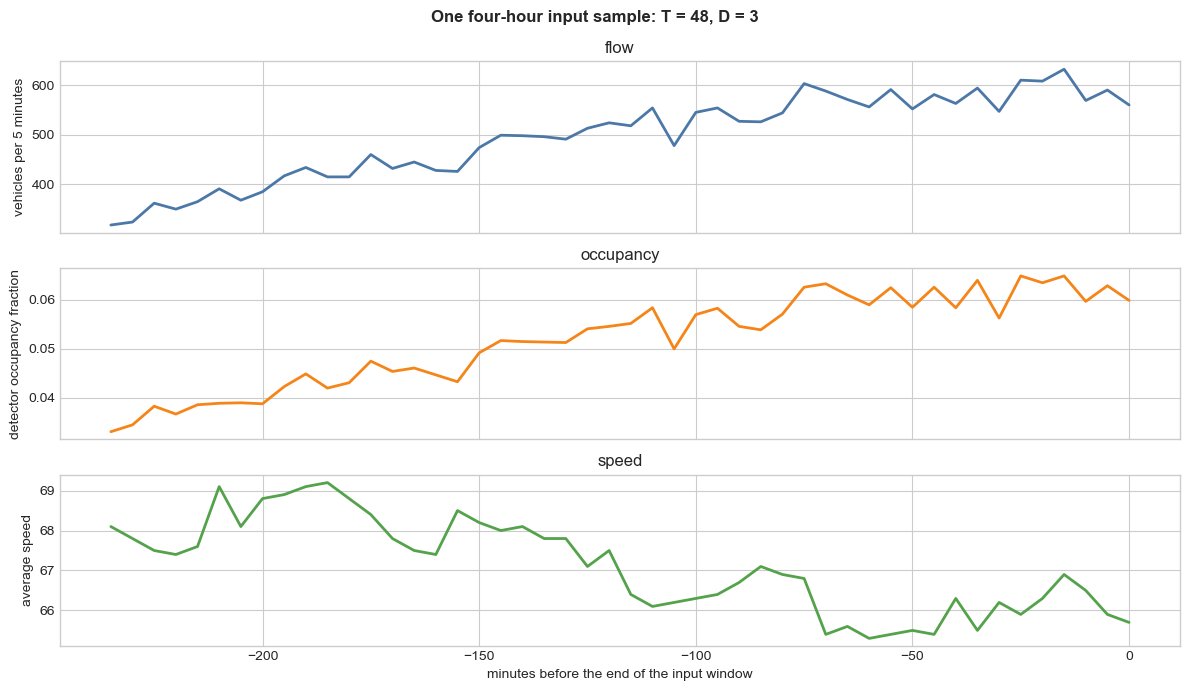

In [7]:
example_scaled = four_hour_data["X_train"][120]
example = example_scaled * feature_std + feature_mean
minutes_before_end = np.arange(-5 * (len(example) - 1), 1, 5)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
plot_settings = [
    ("flow", "vehicles per 5 minutes", "#4C78A8"),
    ("occupancy", "detector occupancy fraction", "#F58518"),
    ("speed", "average speed", "#54A24B"),
]
for feature_index, (feature, label, color) in enumerate(plot_settings):
    axes[feature_index].plot(
        minutes_before_end,
        example[:, feature_index],
        color=color,
        linewidth=2,
    )
    axes[feature_index].set_ylabel(label)
    axes[feature_index].set_title(feature)
axes[-1].set_xlabel("minutes before the end of the input window")
fig.suptitle("One four-hour input sample: T = 48, D = 3", fontweight="bold")
plt.tight_layout()

## 3. Why positional information is necessary

Self-attention alone has no built-in notion of order. A learned positional vector is added to each time token so the model can distinguish "five minutes before the input ends" from "four hours before the input ends".

For a batch of size $B$, the attention layer receives $(B,T,D)$ and returns an attention-weight tensor with shape $(B,H,T,T)$, where $H$ is the number of heads. The last two axes are **query time** and **key time**.

In [8]:
class TemporalAttention(nn.Module):
    def __init__(
        self,
        input_size,
        lookback,
        d_model=32,
        n_heads=4,
        dropout=0.1,
    ):
        super().__init__()
        self.input_projection = nn.Linear(input_size, d_model)
        self.position = nn.Parameter(
            torch.randn(1, lookback, d_model) * 0.02
        )
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 2 * d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * d_model, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, 1)

    def forward(self, x, return_attention=False):
        tokens = self.input_projection(x)
        tokens = tokens + self.position[:, : x.shape[1]]
        attended, attention_weights = self.attention(
            tokens,
            tokens,
            tokens,
            need_weights=True,
            average_attn_weights=False,
        )
        hidden = self.norm1(tokens + attended)
        hidden = self.norm2(hidden + self.feed_forward(hidden))
        prediction = self.output(hidden[:, -1, :])

        if return_attention:
            return prediction, attention_weights
        return prediction


class TrafficANN(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x):
        # ANN input has already been flattened to (N, T × D).
        return self.network(x)


class TrafficLSTM(nn.Module):
    def __init__(self, n_features, hidden_size=48):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        hidden_sequence, _ = self.lstm(x)
        final_hidden_state = hidden_sequence[:, -1, :]
        return self.output(final_hidden_state)


def make_loaders(data, batch_size=128):
    train_dataset = TensorDataset(
        torch.tensor(data["X_train"]),
        torch.tensor(data["y_train"]),
    )
    valid_dataset = TensorDataset(
        torch.tensor(data["X_valid"]),
        torch.tensor(data["y_valid"]),
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=256,
    )
    return train_loader, valid_loader


def fit_model(model, train_loader, valid_loader, epochs=12, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train MAE": [], "valid MAE": []}
    best_valid_loss = float("inf")
    best_state = None

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        train_absolute_error = 0
        train_targets = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            prediction = model(xb)
            loss = loss_fn(prediction, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(xb)
            train_absolute_error += torch.abs((prediction - yb) * flow_std).sum().item()
            train_targets += yb.numel()

        model.eval()
        valid_loss = 0
        valid_absolute_error = 0
        valid_targets = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                prediction = model(xb)
                batch_loss = loss_fn(prediction, yb)
                valid_loss += batch_loss.item() * len(xb)
                valid_absolute_error += torch.abs((prediction - yb) * flow_std).sum().item()
                valid_targets += yb.numel()

        train_loss /= len(train_loader.dataset)
        valid_loss /= len(valid_loader.dataset)
        train_mae = train_absolute_error / train_targets
        valid_mae = valid_absolute_error / valid_targets
        history["train MAE"].append(train_mae)
        history["valid MAE"].append(valid_mae)

        if valid_mae < best_valid_loss:
            best_valid_loss = valid_mae
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"epoch {epoch + 1:02d} | "
            f"train MAE {train_mae:.2f} | "
            f"validation MAE {valid_mae:.2f} vehicles/5 min"
        )

    model.load_state_dict(best_state)
    return history, min(history["valid MAE"])


def predict(model, X, batch_size=256):
    model.eval()
    predictions = []
    loader = DataLoader(
        TensorDataset(torch.tensor(X)),
        batch_size=batch_size,
    )
    with torch.no_grad():
        for (xb,) in loader:
            prediction = model(xb.to(DEVICE))
            predictions.append(prediction.cpu().numpy())
    return np.concatenate(predictions)


def score(name, prediction, target):
    errors = target - prediction
    return {
        "model": name,
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    }

In [9]:
demo_model = TemporalAttention(
    input_size=3,
    lookback=48,
    d_model=32,
    n_heads=4,
).to(DEVICE)
demo_input = torch.tensor(four_hour_data["X_train"][:4]).to(DEVICE)

with torch.no_grad():
    demo_prediction, demo_attention = demo_model(
        demo_input,
        return_attention=True,
    )

print("input (B, T, D):", tuple(demo_input.shape))
print("prediction (B, 1):", tuple(demo_prediction.shape))
print("attention (B, heads, query T, key T):", tuple(demo_attention.shape))

input (B, T, D): (4, 48, 3)
prediction (B, 1): (4, 1)
attention (B, heads, query T, key T): (4, 4, 48, 48)


## 4. Use validation data to choose the lookback

We train two otherwise identical attention models. The only changed hyperparameter is history length: 12 or 48 five-minute intervals. The best validation MAE, expressed as vehicles per five minutes, determines the selected lookback. Test data are not read during this comparison.

In [10]:
attention_candidates = {}
validation_rows = []

for lookback in [12, 48]:
    print(f"\nAttention model with T = {lookback}")
    data = split_windows(lookback=lookback)
    train_loader, valid_loader = make_loaders(data)
    torch.manual_seed(42)

    model = TemporalAttention(
        input_size=3,
        lookback=lookback,
        d_model=32,
        n_heads=4,
    ).to(DEVICE)
    history, best_valid_loss = fit_model(
        model,
        train_loader,
        valid_loader,
        epochs=12,
    )

    attention_candidates[lookback] = {
        "model": model,
        "history": history,
        "data": data,
    }
    validation_rows.append({
        "lookback intervals": lookback,
        "history hours": lookback * 5 / 60,
        "best validation MAE [vehicles/5 min]": best_valid_loss,
    })

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

best_lookback = int(
    validation_results.loc[
        validation_results["best validation MAE [vehicles/5 min]"].idxmin(),
        "lookback intervals",
    ]
)
print("selected lookback:", best_lookback, "intervals")


Attention model with T = 12
epoch 01 | train MAE 74.41 | validation MAE 60.88 vehicles/5 min
epoch 02 | train MAE 59.05 | validation MAE 57.47 vehicles/5 min
epoch 03 | train MAE 55.14 | validation MAE 52.44 vehicles/5 min
epoch 04 | train MAE 52.41 | validation MAE 51.52 vehicles/5 min
epoch 05 | train MAE 50.63 | validation MAE 49.14 vehicles/5 min
epoch 06 | train MAE 48.87 | validation MAE 49.57 vehicles/5 min
epoch 07 | train MAE 47.04 | validation MAE 46.57 vehicles/5 min
epoch 08 | train MAE 44.51 | validation MAE 46.88 vehicles/5 min
epoch 09 | train MAE 43.55 | validation MAE 42.70 vehicles/5 min
epoch 10 | train MAE 42.66 | validation MAE 42.73 vehicles/5 min
epoch 11 | train MAE 42.11 | validation MAE 42.61 vehicles/5 min
epoch 12 | train MAE 41.72 | validation MAE 44.09 vehicles/5 min

Attention model with T = 48
epoch 01 | train MAE 76.55 | validation MAE 56.44 vehicles/5 min
epoch 02 | train MAE 52.33 | validation MAE 50.54 vehicles/5 min
epoch 03 | train MAE 50.29 | val

,lookback intervals,history hours,best validation MAE [vehicles/5 min]
0,12,1.0,42.6131
1,48,4.0,41.4958


selected lookback: 48 intervals


## 5. Compare ANN, LSTM and attention using the selected history

Validation has selected the attention history length and its best training epoch. We now train two baselines using exactly the same historical measurements:

- **ANN:** reshape the sequence from $(N,T,D)$ to a flat design matrix $(N,T\times D)$. The ANN sees all values as ordinary feature columns.
- **LSTM:** keep $(N,T,D)$. The LSTM reads the $T$ time steps in order and carries a recurrent hidden state forward.
- **Temporal attention:** also keep $(N,T,D)$, but each time token can directly compare itself with every other token in the history.

All three models predict one future flow value, so their output is $(N,1)$. Each learned model restores the epoch with its lowest validation MAE. The test period is not used during training or model selection.


ANN input: (7441, 144) = (N, T × D)
LSTM input: (7441, 48, 3) = (N, T, D)
Attention input: (7441, 48, 3) = (N, T, D)
Target for every model: (7441, 1) = (N, 1)
epoch 01 | train MAE 96.08 | validation MAE 68.60 vehicles/5 min
epoch 02 | train MAE 61.82 | validation MAE 63.35 vehicles/5 min
epoch 03 | train MAE 55.06 | validation MAE 58.08 vehicles/5 min
epoch 04 | train MAE 51.16 | validation MAE 54.09 vehicles/5 min
epoch 05 | train MAE 48.86 | validation MAE 50.02 vehicles/5 min
epoch 06 | train MAE 46.51 | validation MAE 48.94 vehicles/5 min
epoch 07 | train MAE 45.40 | validation MAE 50.46 vehicles/5 min
epoch 08 | train MAE 44.80 | validation MAE 47.48 vehicles/5 min
epoch 09 | train MAE 43.25 | validation MAE 45.12 vehicles/5 min
epoch 10 | train MAE 42.41 | validation MAE 43.78 vehicles/5 min
epoch 11 | train MAE 42.06 | validation MAE 47.22 vehicles/5 min
epoch 12 | train MAE 43.07 | validation MAE 45.50 vehicles/5 min
epoch 01 | train MAE 138.05 | validation MAE 93.30 vehicles/

,model,best validation MAE
0,ANN,43.781
1,LSTM,42.143
2,Temporal attention,41.496


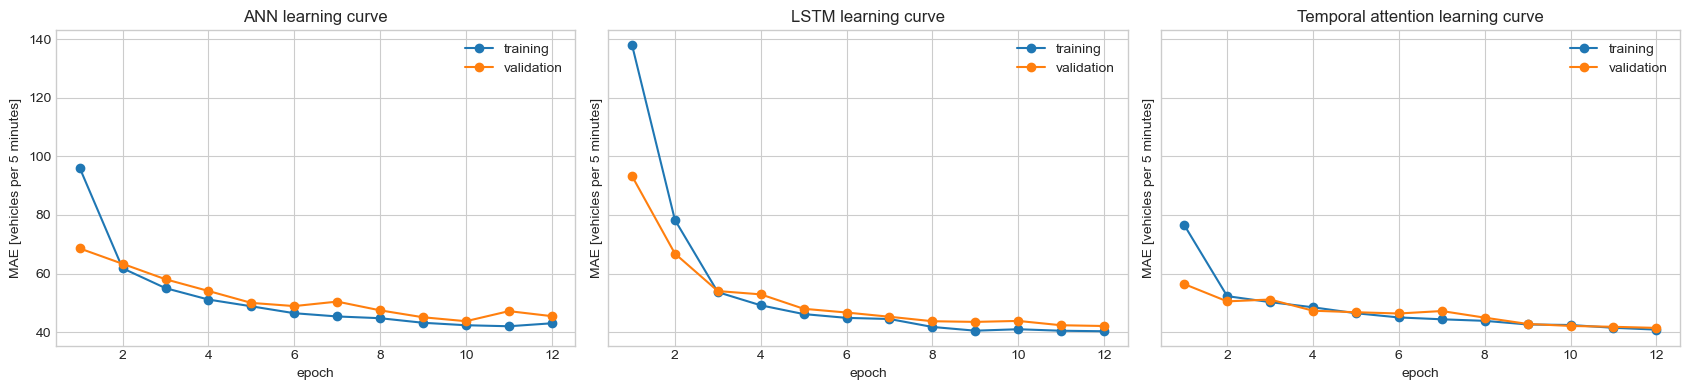

In [11]:
selected = attention_candidates[best_lookback]
selected_data = selected["data"]
attention_model = selected["model"]

# LSTM and attention retain the sequence axes: (N, T, D).
X_train_sequence = selected_data["X_train"]
X_valid_sequence = selected_data["X_valid"]
X_test_sequence = selected_data["X_test"]

# The ANN receives the same measurements flattened to: (N, T × D).
X_train_ann = X_train_sequence.reshape(len(X_train_sequence), -1)
X_valid_ann = X_valid_sequence.reshape(len(X_valid_sequence), -1)
X_test_ann = X_test_sequence.reshape(len(X_test_sequence), -1)

ann_data = {
    "X_train": X_train_ann,
    "y_train": selected_data["y_train"],
    "X_valid": X_valid_ann,
    "y_valid": selected_data["y_valid"],
}
ann_train_loader, ann_valid_loader = make_loaders(ann_data)
lstm_train_loader, lstm_valid_loader = make_loaders(selected_data)

print("ANN input:", X_train_ann.shape, "= (N, T × D)")
print("LSTM input:", X_train_sequence.shape, "= (N, T, D)")
print("Attention input:", X_train_sequence.shape, "= (N, T, D)")
print("Target for every model:", selected_data["y_train"].shape, "= (N, 1)")

torch.manual_seed(42)
ann_model = TrafficANN(
    input_size=best_lookback * 3,
    hidden_size=64,
).to(DEVICE)
ann_history, ann_valid_loss = fit_model(
    ann_model,
    ann_train_loader,
    ann_valid_loader,
    epochs=12,
)

torch.manual_seed(42)
lstm_model = TrafficLSTM(
    n_features=X_train_sequence.shape[2],
    hidden_size=48,
).to(DEVICE)
lstm_history, lstm_valid_loss = fit_model(
    lstm_model,
    lstm_train_loader,
    lstm_valid_loader,
    epochs=12,
)

validation_summary = pd.DataFrame([
    {"model": "ANN", "best validation MAE": ann_valid_loss},
    {"model": "LSTM", "best validation MAE": lstm_valid_loss},
    {
        "model": "Temporal attention",
        "best validation MAE": min(selected["history"]["valid MAE"]),
    },
])
display(validation_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
learning_curves = {
    "ANN": ann_history,
    "LSTM": lstm_history,
    "Temporal attention": selected["history"],
}
for ax, (model_name, history) in zip(axes, learning_curves.items()):
    epochs = np.arange(1, len(history["train MAE"]) + 1)
    ax.plot(epochs, history["train MAE"], marker="o", label="training")
    ax.plot(epochs, history["valid MAE"], marker="o", label="validation")
    ax.set_title(f"{model_name} learning curve")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MAE [vehicles per 5 minutes]")
    ax.legend()
plt.tight_layout()


## 6. Final test comparison

Validation has now fixed the history length and best stopping epoch for every learned model. We evaluate persistence, ANN, LSTM and temporal attention on the test period once. Persistence predicts that future flow equals the last flow observed in the input window. The three neural networks use the same historical measurements and the same target; only their input representation and sequence-processing architecture differ.


In [12]:
X_test = selected_data["X_test"]
y_test = selected_data["y_test"]

test_truth = y_test * flow_std + flow_mean
test_persistence = X_test[:, -1, 0:1] * flow_std + flow_mean
test_ann = predict(ann_model, X_test_ann) * flow_std + flow_mean
test_lstm = predict(lstm_model, X_test_sequence) * flow_std + flow_mean
test_attention = predict(attention_model, X_test_sequence) * flow_std + flow_mean

test_results = pd.DataFrame([
    score("Persistence", test_persistence, test_truth),
    score("ANN", test_ann, test_truth),
    score("LSTM", test_lstm, test_truth),
    score("Temporal attention", test_attention, test_truth),
])
display(test_results.round(3))


,model,MAE,RMSE
0,Persistence,73.554001,101.072998
1,ANN,49.595001,69.414001
2,LSTM,48.923000,68.996002
3,Temporal attention,48.194000,68.500999


## 7. Read predictions and attention weights

The first plot shows how predictions follow two days of held-out flow. The attention plots then inspect one held-out sample:

- in the heatmap, the vertical axis is the query time being updated, the horizontal axis is the historical key time receiving weight, and darker colour means more weight;
- in the line plot, only the **final query** is shown because its hidden representation is used for prediction; each line is one attention head;
- zero minutes means the final observation in the input window, while negative values refer to earlier history.

Attention weights describe internal routing, not causal effects.

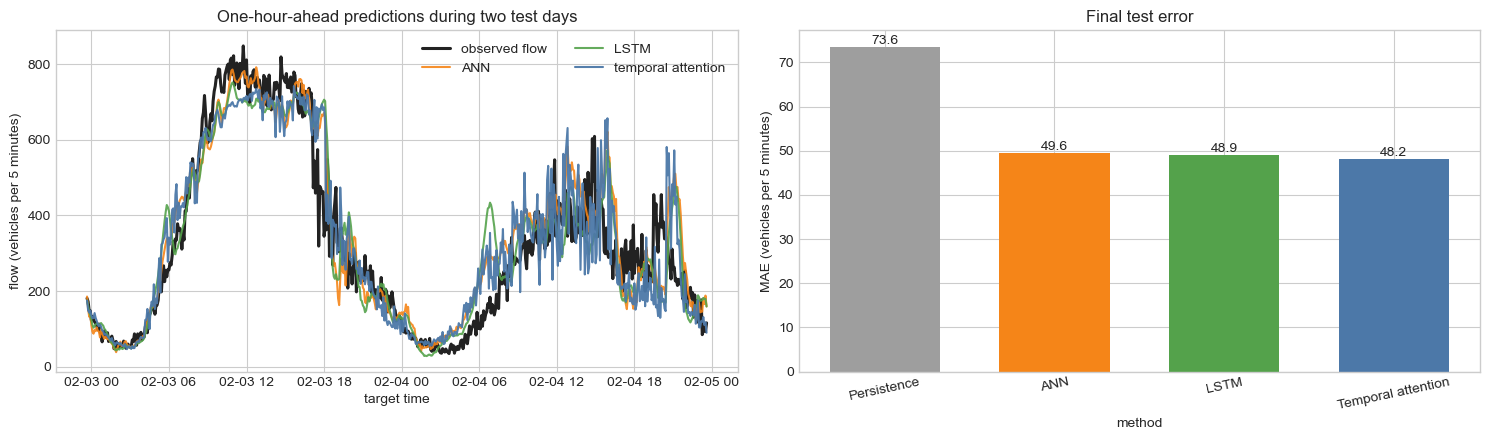

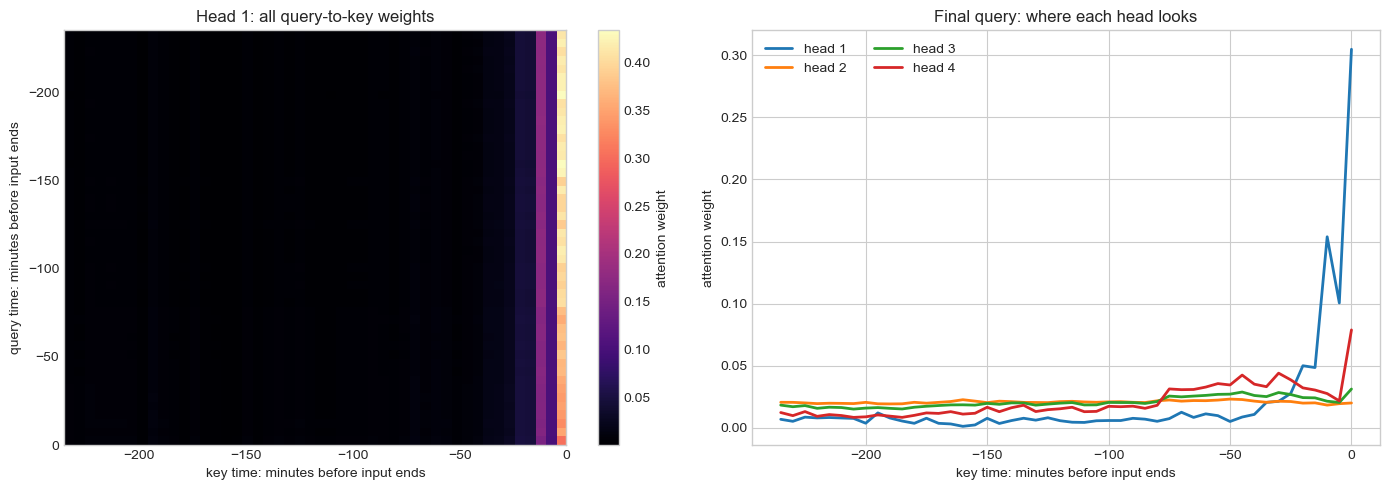

In [13]:
test_times = traffic.index[selected_data["test_positions"]]
window = slice(0, 2 * 24 * 12)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(
    test_times[window],
    test_truth[window, 0],
    color="#222222",
    linewidth=2.2,
    label="observed flow",
)
axes[0].plot(
    test_times[window],
    test_ann[window, 0],
    color="#F58518",
    alpha=0.9,
    label="ANN",
)
axes[0].plot(
    test_times[window],
    test_lstm[window, 0],
    color="#54A24B",
    alpha=0.9,
    label="LSTM",
)
axes[0].plot(
    test_times[window],
    test_attention[window, 0],
    color="#4C78A8",
    alpha=0.95,
    label="temporal attention",
)
axes[0].set_title("One-hour-ahead predictions during two test days")
axes[0].set_xlabel("target time")
axes[0].set_ylabel("flow (vehicles per 5 minutes)")
axes[0].legend(ncol=2)

bar_colors = ["#9E9E9E", "#F58518", "#54A24B", "#4C78A8"]
axes[1].bar(
    test_results["model"],
    test_results["MAE"],
    color=bar_colors,
    width=0.65,
)
axes[1].set_title("Final test error")
axes[1].set_xlabel("method")
axes[1].set_ylabel("MAE (vehicles per 5 minutes)")
axes[1].tick_params(axis="x", rotation=12)
for index, value in enumerate(test_results["MAE"]):
    axes[1].text(index, value, f"{value:.1f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

sample_id = int(np.argmax(np.abs(test_truth[:, 0] - test_persistence[:, 0])))
sample_tensor = torch.tensor(X_test[sample_id : sample_id + 1]).to(DEVICE)
with torch.no_grad():
    _, attention_weights = attention_model(
        sample_tensor,
        return_attention=True,
    )
attention_weights = attention_weights.cpu().numpy()[0]
minutes = np.arange(-5 * (best_lookback - 1), 1, 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
heatmap = axes[0].imshow(
    attention_weights[0],
    cmap="magma",
    aspect="auto",
    extent=[minutes[0], minutes[-1], minutes[-1], minutes[0]],
)
axes[0].grid(False)
axes[0].set_title("Head 1: all query-to-key weights")
axes[0].set_xlabel("key time: minutes before input ends")
axes[0].set_ylabel("query time: minutes before input ends")
fig.colorbar(heatmap, ax=axes[0], label="attention weight")

for head in range(attention_weights.shape[0]):
    axes[1].plot(
        minutes,
        attention_weights[head, -1],
        linewidth=2,
        label=f"head {head + 1}",
    )
axes[1].set_title("Final query: where each head looks")
axes[1].set_xlabel("key time: minutes before input ends")
axes[1].set_ylabel("attention weight")
axes[1].legend(ncol=2)
plt.tight_layout()
plt.show()

## What to remember

- The raw sequence is $(N,T,D)$: here $D=3$ means flow, occupancy and speed from one detector.
- The ANN explicitly flattens this to $(N,T\times D)$, whereas LSTM and attention retain $(N,T,D)$. The models therefore use the same measurements but process their structure differently.
- LSTM is a recurrent sequence baseline. Any advantage of attention should be judged against LSTM as well as ANN and persistence.
- Attention weights form a query-time × key-time matrix; every query row sums to one.
- Position must be represented explicitly because self-attention does not know temporal order by itself.
- A longer history is a hyperparameter, not an automatic improvement; choose it on validation data.
- Multiple heads may route information differently, but their weights are not causal explanations.
- Single-step attention can be extended to multi-step prediction by replacing the final output layer with $H$ outputs, giving target shape $(N,H,1)$.
